# Motor Insurance Analytics – insurance_analysis.ipynb

End-to-end EDA + KPI analysis for the Motor Insurance Analytics Dashboard project.

**Tables:** customers | vehicles | policies | claims | payments

## 1. Setup

In [1]:
import os
import warnings

In [2]:
warnings.filterwarnings('ignore')
import numpy as np

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
import seaborn as sns
sns.set_theme(style='whitegrid')

In [5]:
pd.set_option('display.max_columns', 40)
pd.set_option('display.float_format', '{:.2f}'.format)

In [6]:
plt.rcParams['figure.figsize'] = (11, 5)
DATA_DIR = 'data/raw'   # change to 'data/cleaned' if needed

## 2. Load Data

In [7]:
tables = ['customers', 'vehicles', 'policies', 'claims', 'payments']
data = {}

In [8]:
# Cell 1 – set the path to your data folder
DATA_DIR = r"C:\Users\user\Downloads\vscode\insurance\data\raw"

In [9]:
# Cell 2 – load all tables
for t in tables:
    path = os.path.join(DATA_DIR, f"{t}.csv")
    if not os.path.exists(path):
        # fallback to cleaned folder if raw file is missing
        cleaned_dir = r"C:\Users\user\Downloads\vscode\insurance\data\cleaned"
        path = os.path.join(cleaned_dir, f"{t}_cleaned.csv")
    data[t] = pd.read_csv(path)
    print(f"{t:12s} → {data[t].shape}")

customers    → (20000, 8)
vehicles     → (25000, 8)
policies     → (25000, 10)
claims       → (10000, 12)
payments     → (7000, 7)


In [10]:
customers = data['customers']
vehicles  = data['vehicles']

In [11]:
policies = data['policies']
claims   = data['claims']

In [12]:
payments = data['payments']
print('All tables loaded.')

All tables loaded.


## 3. Quick Peek

In [13]:
customers.head(3)

,customer_id,customer_name,gender,date_of_birth,age,city,state,occupation
0,CUST_000001,Aryan Maharaj,Male,1980-09-27,46,Bengaluru,Karnataka,Business Owner
1,CUST_000002,Udant Dewan,Male,1990-08-03,36,Chennai,Tamil Nadu,Sales Executive
2,CUST_000003,Gagan Sami,Male,1969-06-01,57,Karimnagar,Telangana,Software Engineer


In [14]:
vehicles.head(3)

,vehicle_id,customer_id,vehicle_type,vehicle_make,vehicle_model,vehicle_year,fuel_type,vehicle_value
0,VEH_000001,CUST_000216,Car,Tata,Tiago,2023,Petrol,602727.06
1,VEH_000002,CUST_011180,Car,Tata,Punch,2023,CNG,860471.13
2,VEH_000003,CUST_012391,Car,Hyundai,i20,2017,Diesel,751541.48


In [15]:
policies.head(3)

,policy_id,customer_id,vehicle_id,policy_start_date,policy_end_date,policy_type,premium_amount,coverage_amount,policy_status,payment_frequency
0,POL_000001,CUST_000216,VEH_000001,2026-04-10,2027-04-09,Comprehensive,18799.02,572309.02,Active,Annual
1,POL_000002,CUST_011180,VEH_000002,2024-09-30,2025-09-29,Comprehensive,24413.33,812763.96,Renewed,Semi-Annual
2,POL_000003,CUST_012391,VEH_000003,2024-01-30,2025-01-29,Comprehensive,27496.06,738543.68,Expired,Annual


In [16]:
claims.head(3)

,claim_id,policy_id,customer_id,claim_date,accident_date,claim_type,accident_location,claim_amount,claim_status,approval_date,settlement_date,damage_severity
0,CLM_000001,POL_011277,CUST_018960,2025-01-13,2025-01-07,Third Party Damage,City Road,256572.56,Settled,2025-01-24,2025-01-31,Low
1,CLM_000002,POL_020774,CUST_003532,2026-05-25,2026-05-12,Accident,Parking Area,141080.87,Pending,NaN,NaN,Low
2,CLM_000003,POL_023289,CUST_009274,2024-04-19,2024-04-17,Third Party Damage,"Phusro, West Bengal",95522.84,Rejected,NaN,NaN,Low


In [17]:
payments.head(3)

,payment_id,claim_id,policy_id,payment_date,payment_amount,payment_status,payment_method
0,PAY_000001,CLM_004650,POL_002355,2025-12-02,59275.42,Completed,Bank Transfer
1,PAY_000002,CLM_002291,POL_021490,2025-09-08,91119.70,Completed,UPI
2,PAY_000003,CLM_003111,POL_024892,2025-06-19,331851.20,Completed,Cheque


## 4. Data Quality

In [18]:
for name, df in data.items():
    print(f'{name:12s} | rows={len(df):,} | dups={df.duplicated().sum()} | nulls={df.isnull().sum().sum()}')

customers    | rows=20,000 | dups=0 | nulls=0
vehicles     | rows=25,000 | dups=0 | nulls=0
policies     | rows=25,000 | dups=0 | nulls=0
claims       | rows=10,000 | dups=0 | nulls=9692
payments     | rows=7,000 | dups=0 | nulls=0


In [19]:
claims.isnull().sum()

claim_id                0
policy_id               0
customer_id             0
claim_date              0
accident_date           0
claim_type              0
accident_location       0
claim_amount            0
claim_status            0
approval_date        2951
settlement_date      6741
damage_severity         0
dtype: int64

## 5. Type Conversion

In [20]:
date_map = {
    'customers': ['date_of_birth'],
    'policies' : ['policy_start_date', 'policy_end_date'],
    'claims'   : ['claim_date', 'accident_date', 'approval_date', 'settlement_date'],
    'payments' : ['payment_date']
}

In [21]:
for table, cols in date_map.items():
    for col in cols:
        if col in data[table].columns:
            data[table][col] = pd.to_datetime(data[table][col], errors='coerce')

In [22]:
num_map = {
    'customers': ['age'],
    'vehicles' : ['vehicle_year', 'vehicle_value'],
    'policies' : ['premium_amount', 'coverage_amount'],
    'claims'   : ['claim_amount'],
    'payments' : ['payment_amount']
}

In [23]:
for table, cols in num_map.items():
    for col in cols:
        if col in data[table].columns:
            data[table][col] = pd.to_numeric(data[table][col], errors='coerce')

In [24]:
customers = data['customers']
vehicles  = data['vehicles']
policies  = data['policies']
claims    = data['claims']
payments  = data['payments']

## 6. Derived Columns

In [25]:
policies['policy_duration_days'] = (policies['policy_end_date'] - policies['policy_start_date']).dt.days
policies['policy_active_flag']   = (policies['policy_status'] == 'Active').astype(int)

In [26]:
today = pd.Timestamp.today()
customers['customer_age'] = ((today - customers['date_of_birth']).dt.days / 365.25).round().astype('Int64')

In [27]:
vehicles['vehicle_age'] = today.year - vehicles['vehicle_year']
print('Vehicle age created.')

Vehicle age created.


In [28]:
claims['claim_processing_days'] = (claims['approval_date'] - claims['claim_date']).dt.days
claims['claim_settlement_days'] = (claims['settlement_date'] - claims['claim_date']).dt.days

In [29]:
data['policies']  = policies
data['customers'] = customers
data['vehicles']  = vehicles
data['claims']    = claims

## 7. EDA – Policy Status

In [30]:
status_counts = policies['policy_status'].value_counts()
status_counts

policy_status
Expired      10464
Active        7551
Renewed       6665
Cancelled      320
Name: count, dtype: int64

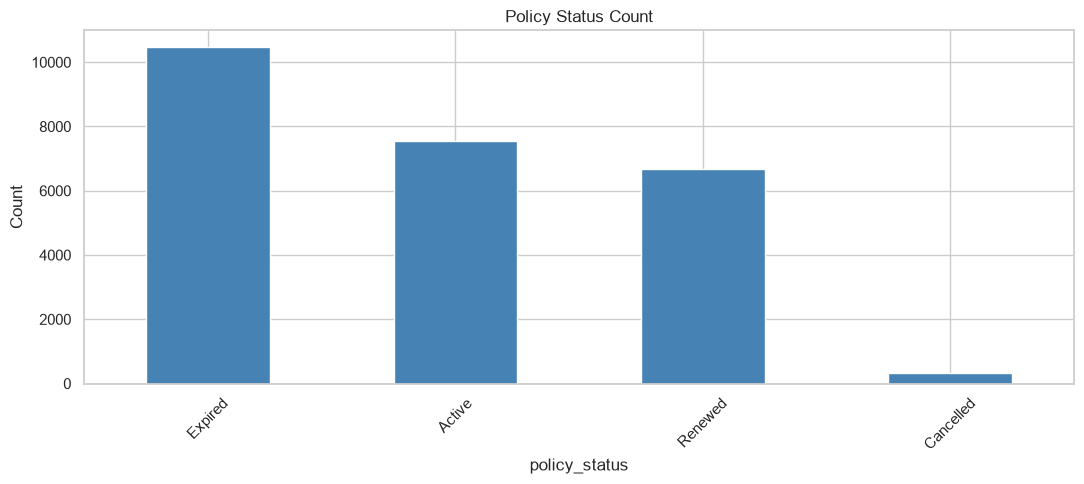

In [31]:
status_counts.plot(kind='bar', color='steelblue', title='Policy Status Count')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

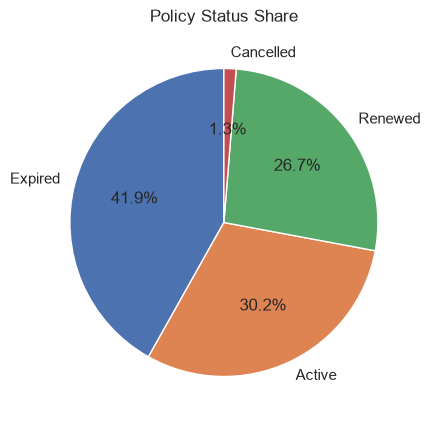

In [32]:
status_counts.plot(kind='pie', autopct='%1.1f%%', startangle=90, title='Policy Status Share')
plt.ylabel('')
plt.show()

## 8. EDA – Premium by Policy Type

In [33]:
prem_by_type = policies.groupby('policy_type')['premium_amount'].agg(['sum', 'mean', 'count'])
prem_by_type = prem_by_type.sort_values('sum', ascending=False)
prem_by_type

,sum,mean,count
policy_type,,,
Comprehensive,544963562.39,36126.19,15085
Zero Depreciation,175078267.04,47318.45,3700
Third Party,75526942.28,12152.36,6215


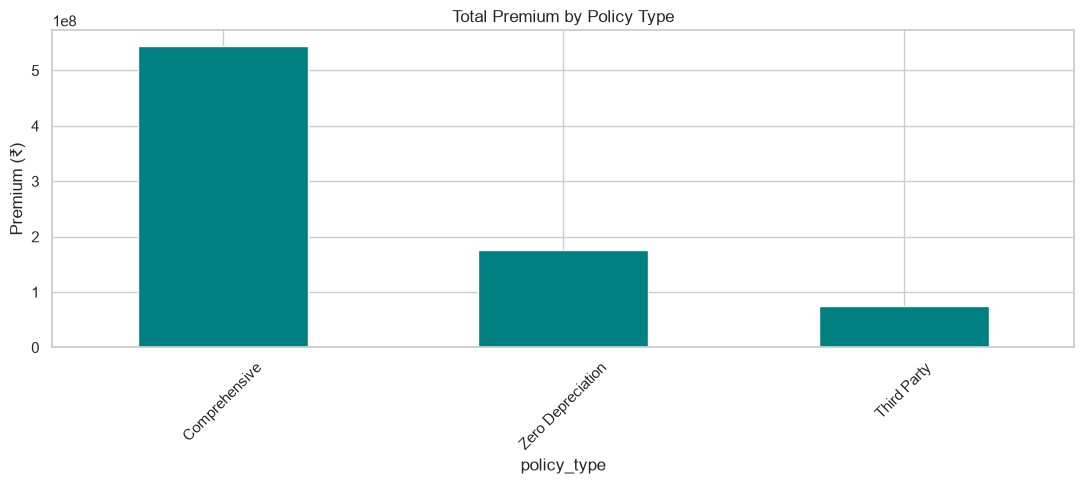

In [34]:
prem_by_type['sum'].plot(kind='bar', color='teal', title='Total Premium by Policy Type')
plt.ylabel('Premium (₹)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 9. EDA – Claims Status & Amount

In [35]:
claim_status = claims['claim_status'].value_counts()
claim_status

claim_status
Approved    3790
Settled     3259
Pending     1791
Rejected    1160
Name: count, dtype: int64

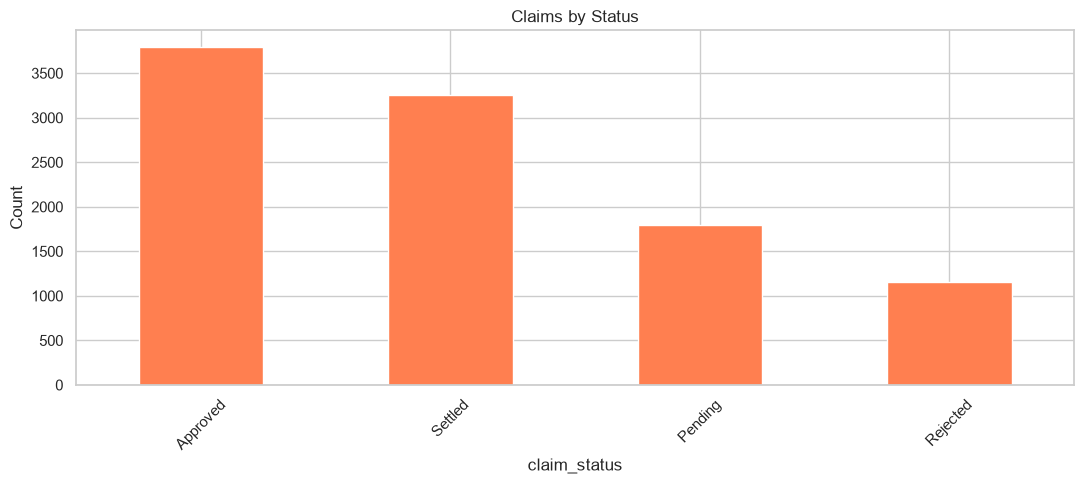

In [36]:
claim_status.plot(kind='bar', color='coral', title='Claims by Status')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

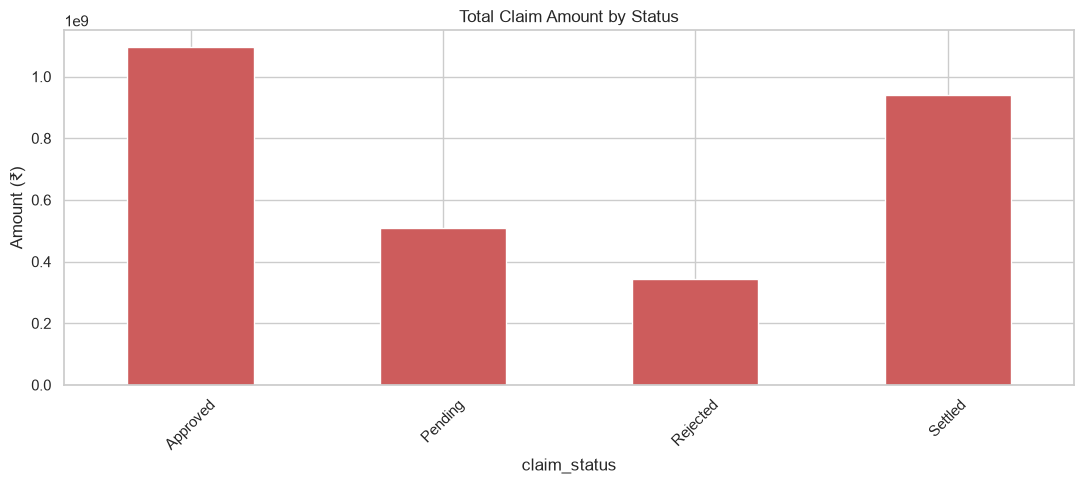

In [37]:
claims.groupby('claim_status')['claim_amount'].sum().plot(kind='bar', color='indianred', title='Total Claim Amount by Status')
plt.ylabel('Amount (₹)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

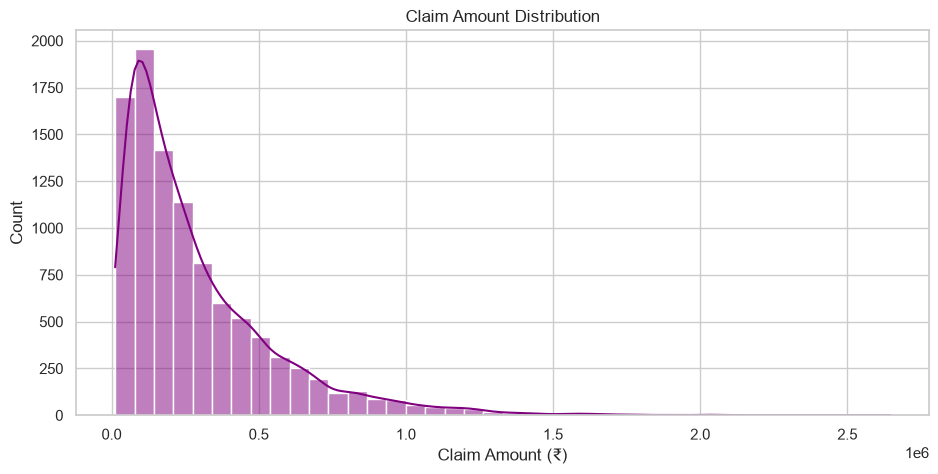

In [38]:
sns.histplot(claims['claim_amount'], bins=40, kde=True, color='purple')
plt.title('Claim Amount Distribution')
plt.xlabel('Claim Amount (₹)')
plt.show()

In [39]:
claims['claim_amount'].describe()

count     10000.00
mean     288543.64
std      263048.10
min       12281.47
25%      101711.52
50%      205040.10
75%      391884.29
max     2645659.52
Name: claim_amount, dtype: float64

## 10. Claims by Vehicle Type

In [40]:
clm_veh = (claims[['claim_id', 'policy_id', 'claim_amount']]
           .merge(policies[['policy_id', 'vehicle_id']], on='policy_id')
           .merge(vehicles[['vehicle_id', 'vehicle_type']], on='vehicle_id'))

In [41]:
veh_claims = (clm_veh.groupby('vehicle_type')
              .agg(total_claims=('claim_id', 'count'),
                   total_amount=('claim_amount', 'sum'),
                   avg_amount=('claim_amount', 'mean'))
              .sort_values('total_amount', ascending=False))
veh_claims

,total_claims,total_amount,avg_amount
vehicle_type,,,
Car,10000,2885436440.65,288543.64


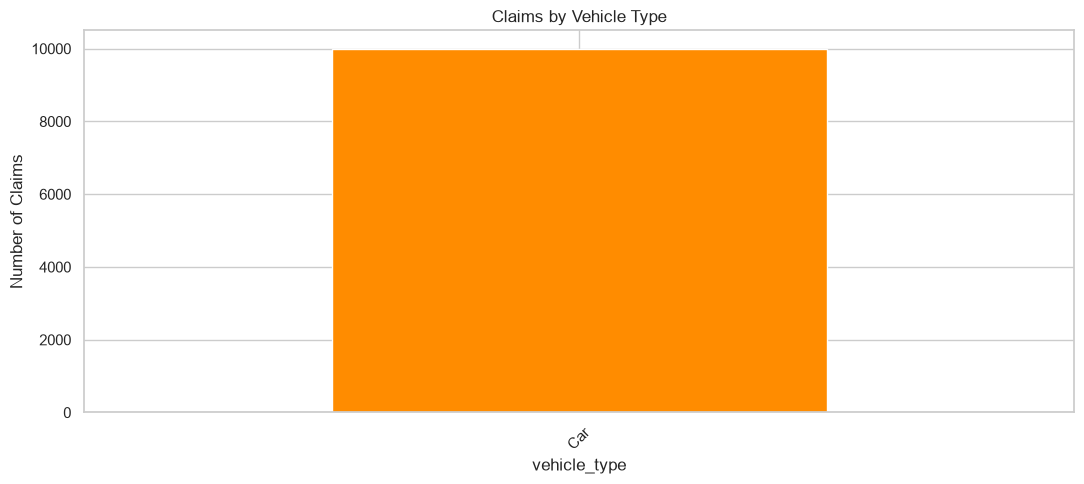

In [42]:
veh_claims['total_claims'].plot(kind='bar', color='darkorange', title='Claims by Vehicle Type')
plt.ylabel('Number of Claims')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 11. Customer Age vs Claims

In [43]:
cust_claims = (claims[['customer_id', 'claim_amount']]
               .merge(customers[['customer_id', 'customer_age', 'gender', 'state']], on='customer_id'))

In [44]:
cust_claims['age_group'] = pd.cut(
    cust_claims['customer_age'],
    bins=[0, 25, 35, 45, 55, 65, 100],
    labels=['18-25', '26-35', '36-45', '46-55', '56-65', '65+']
)

In [45]:
age_summary = cust_claims.groupby('age_group', observed=True).agg(
    claims=('claim_amount', 'count'),
    total_amount=('claim_amount', 'sum'),
    avg_amount=('claim_amount', 'mean')
)
age_summary

,claims,total_amount,avg_amount
age_group,,,
18-25,1400,407094394.12,290781.71
26-35,1877,539088755.67,287207.65
36-45,1899,550037226.67,289645.72
46-55,1910,551658223.34,288826.29
56-65,1951,567010327.98,290625.49
65+,963,270547512.87,280942.38


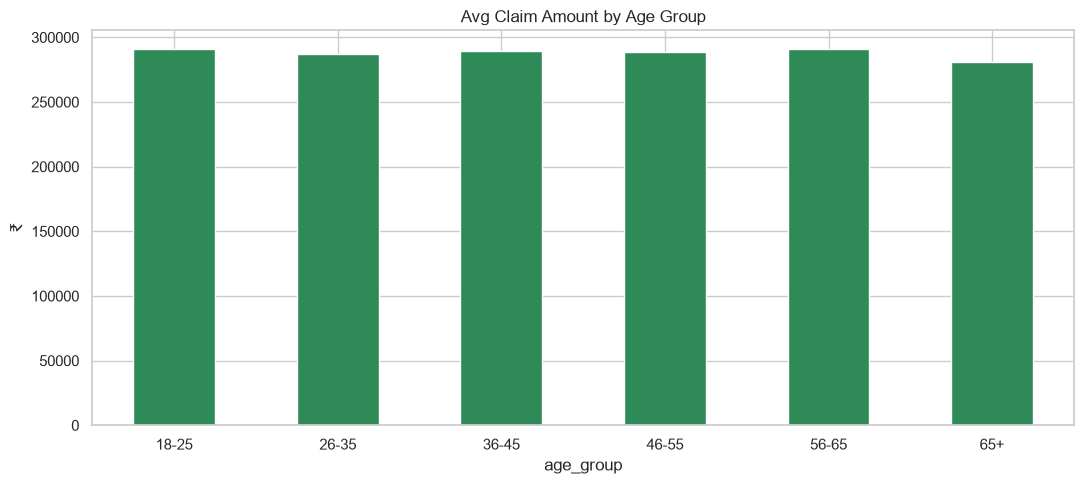

In [46]:
age_summary['avg_amount'].plot(kind='bar', color='seagreen', title='Avg Claim Amount by Age Group')
plt.ylabel('₹')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 12. KPI Summary

In [47]:
total_customers    = customers['customer_id'].nunique()
total_policies     = policies['policy_id'].nunique()

In [48]:
active_policies    = (policies['policy_status'] == 'Active').sum()
expired_policies   = (policies['policy_status'] == 'Expired').sum()

In [49]:
cancelled_policies = (policies['policy_status'] == 'Cancelled').sum()
renewed_policies   = (policies['policy_status'] == 'Renewed').sum()

In [50]:
total_premium      = policies['premium_amount'].sum()
avg_premium        = policies['premium_amount'].mean()

In [51]:
avg_coverage       = policies['coverage_amount'].mean()
total_claims       = claims['claim_id'].nunique()

In [52]:
approved_claims    = (claims['claim_status'] == 'Approved').sum()
rejected_claims    = (claims['claim_status'] == 'Rejected').sum()

In [53]:
pending_claims     = (claims['claim_status'] == 'Pending').sum()
settled_claims     = (claims['claim_status'] == 'Settled').sum()

In [54]:
total_claim_amt    = claims['claim_amount'].sum()
avg_claim_amt      = claims['claim_amount'].mean()

In [55]:
approval_rate      = approved_claims / total_claims * 100 if total_claims else 0
rejection_rate     = rejected_claims / total_claims * 100 if total_claims else 0

In [56]:
avg_processing     = claims['claim_processing_days'].mean()
avg_settlement     = claims['claim_settlement_days'].mean()

In [57]:
total_payments     = payments['payment_amount'].sum()
claim_to_premium   = total_claim_amt / total_premium if total_premium else 0

In [58]:
print('=' * 58)
print('MOTOR INSURANCE – KEY PERFORMANCE INDICATORS')
print('=' * 58)

MOTOR INSURANCE – KEY PERFORMANCE INDICATORS


In [59]:
print(f'Total Customers              : {total_customers:,}')
print(f'Total Policies               : {total_policies:,}')

Total Customers              : 20,000
Total Policies               : 25,000


In [60]:
print(f'  Active                     : {active_policies:,}')
print(f'  Expired                    : {expired_policies:,}')

  Active                     : 7,551
  Expired                    : 10,464


In [ ]:
print(f'  Cancelled                  : {cancelled_policies:,}')
print(f'  Renewed                    : {renewed_policies:,}')

In [ ]:
print('-' * 58)
print(f'Total Premium Collected      : ₹{total_premium:,.0f}')

In [ ]:
print(f'Average Premium              : ₹{avg_premium:,.0f}')
print(f'Average Coverage             : ₹{avg_coverage:,.0f}')

In [ ]:
print('-' * 58)
print(f'Total Claims                 : {total_claims:,}')

In [ ]:
print(f'  Approved                   : {approved_claims:,}')
print(f'  Rejected                   : {rejected_claims:,}')

In [ ]:
print(f'  Pending                    : {pending_claims:,}')
print(f'  Settled                    : {settled_claims:,}')

In [ ]:
print(f'Approval Rate                : {approval_rate:.1f}%')
print(f'Rejection Rate               : {rejection_rate:.1f}%')

In [ ]:
print('-' * 58)
print(f'Total Claim Amount           : ₹{total_claim_amt:,.0f}')

In [ ]:
print(f'Average Claim Amount         : ₹{avg_claim_amt:,.0f}')
print(f'Claim-to-Premium Ratio       : {claim_to_premium:.2f}')

In [ ]:
print('-' * 58)
print(f'Avg Claim Processing Days    : {avg_processing:.1f}')

In [ ]:
print(f'Avg Claim Settlement Days    : {avg_settlement:.1f}')
print(f'Total Payments Made          : ₹{total_payments:,.0f}')

In [ ]:
print('=' * 58)

## 13. Extra Insights

In [ ]:
top_states = (cust_claims.groupby('state')['claim_amount']
              .sum().sort_values(ascending=False).head(10))
top_states

In [ ]:
top_states.plot(kind='barh', color='slateblue', title='Top 10 States – Total Claim Amount')
plt.xlabel('₹')
plt.tight_layout()
plt.show()

In [ ]:
if 'damage_severity' in claims.columns:
    sev = claims['damage_severity'].value_counts()
    print(sev)
    sev.plot(kind='pie', autopct='%1.1f%%', startangle=90,
             colors=['#2ecc71', '#f1c40f', '#e74c3c'], title='Damage Severity')
    plt.ylabel('')
    plt.show()

In [ ]:
if 'claim_type' in claims.columns:
    ct = (claims.groupby('claim_type')
          .agg(count=('claim_id', 'count'),
               total_amt=('claim_amount', 'sum'),
               avg_amt=('claim_amount', 'mean'))
          .sort_values('total_amt', ascending=False))
    display(ct)

In [ ]:
if 'claim_type' in claims.columns:
    ct['count'].plot(kind='bar', color='mediumvioletred', title='Claims by Type')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

## 14. Save Cleaned Tables (optional)

In [ ]:
os.makedirs('data/cleaned_from_notebook', exist_ok=True)
print('Output folder ready.')

In [ ]:
for name, df in data.items():
    out = f'data/cleaned_from_notebook/{name}_cleaned.csv'
    df.to_csv(out, index=False)
    print(f'Saved → {out}')

---
**Done.**  
Place this notebook in the project root (or adjust `DATA_DIR`).  
Run all cells after the CSVs are present under `data/raw/`.